# 실습 1. 학습 없이 써 보기: CNN 추론
**통계청 AI 교육 · 2026.10.27(화)**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sunghoonim/stat-ai-2026/blob/main/lab1_cnn_inference.ipynb)

### 오늘의 목표
- Loss · Optimizer(학습)를 배우기 **전에**, 이미 학습된 **CNN**을 **그대로 써 보며**(추론, inference) 속을 들여다본다
  1. 사진을 분류해 보고, 모델을 바꿔 가며 비교 (AlexNet · VGG · ResNet · ViT)
  2. 필터가 사진을 훑는 계산을 직접 해 보고, 층마다 무엇을 보는지 확인
- 이번 실습에서는 **가중치를 한 번도 바꾸지 않습니다.** 가중치를 어떻게 정하는지는 Loss · Optimizer 강의와 실습 3에서

| 단계 | 내용 | 시간 |
|---|---|---|
| 1단계 | 사전학습 ResNet18로 사진 분류 → 모델 5개(AlexNet · VGG · ResNet · ViT)로 바꿔 보기 | 10분 |
| 2단계 | CNN 들여다보기: 필터 직접 계산 · 1층 필터 · 층별 특징 맵 | 5분 |
| 도전 | Gemini로 이 노트북 바꿔 보기 (맨 아래) | 5분 |

**합계 20분** · CNN 강의 뒤에 모두 함께 합니다. Transformer는 **실습 2**(Transformer 강의 뒤)에서 합니다. **CPU로 충분합니다.**

### 사용법
- 셀을 위에서부터 하나씩 실행합니다 (`Shift + Enter`). 실행 결과가 미리 저장되어 있으니, 막히면 결과를 보며 따라와도 됩니다.
- `#@title`이 붙은 칸은 그림 그리는 도우미입니다. 실행만 하면 됩니다.

> **추론(inference)이란?** 학습 = 데이터로 가중치를 고치는 일, 추론 = **고정된 가중치**로 새 입력의 답을 계산하는 일.
> 통계로 말하면, 이미 추정한 회귀식에 **새 x를 넣어 ŷ를 계산**하는 것과 같습니다.

## 0. 준비

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models
from skimage import data as skdata   # 예시 사진 (scikit-image에 들어 있는 공개 사진)

torch.manual_seed(0)
torch.set_grad_enabled(False)         # 이번 실습은 추론만: 기울기(학습용 계산)를 끕니다
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)

PyTorch 2.14.1 | torchvision 0.29.1


In [2]:
#@title 🎨 그림 도우미 함수 (실행만 하세요. 내용은 몰라도 됩니다)
plt.rcParams.update({"figure.dpi": 90})

def show_row(imgs, titles=None, size=2.6, cmap=None, suptitle=""):
    fig, axes = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size + (0.5 if suptitle else 0.2)))
    for i, (ax, im) in enumerate(zip(np.atleast_1d(axes), imgs)):
        ax.imshow(im, cmap=cmap); ax.axis("off")
        if titles: ax.set_title(titles[i], fontsize=9)
    if suptitle: fig.suptitle(suptitle, fontsize=11)
    fig.tight_layout(); plt.show()

def norm01(a):
    a = np.asarray(a, dtype=float)
    return (a - a.min()) / (a.max() - a.min() + 1e-8)

---
## 1단계. CNN: 사전학습 ResNet18로 사진 분류 (10분)
**ResNet18**은 강의 'ResNet: ILSVRC 2015 winner' 장에 나온 **ResNet**(152층)의 작은 형제(18층)입니다. **ImageNet** 사진 약 128만 장 · 1,000종으로 **이미 학습된 가중치**를 내려받아(약 45MB) 그대로 씁니다.

In [3]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
cnn = models.resnet18(weights=weights).eval()          # eval(): 추론 모드
preprocess = weights.transforms()                       # 학습 때와 같은 방식으로 사진 크기 · 밝기 맞추기
CATEGORIES = weights.meta["categories"]                 # 1,000개 분류 이름 (영어)
n_params = sum(p.numel() for p in cnn.parameters())
print(f"ResNet18 가중치 {n_params:,}개 | 분류 {len(CATEGORIES):,}종 | 예: {CATEGORIES[:5]}")

ResNet18 가중치 11,689,512개 | 분류 1,000종 | 예: ['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead']


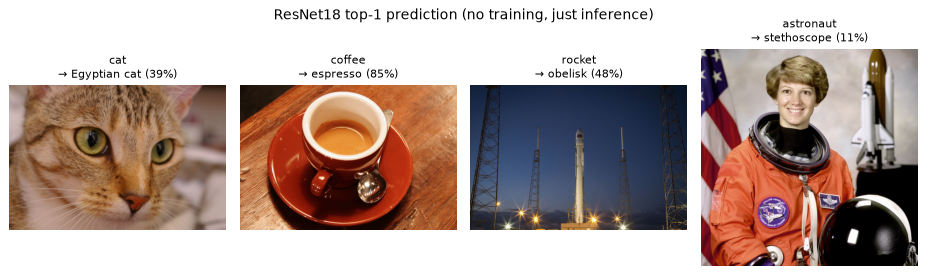

,cat,coffee,rocket,astronaut
1위,Egyptian cat (39.1%),espresso (85.2%),obelisk (48.1%),stethoscope (11.4%)
2위,tiger cat (38.7%),chocolate sauce (4.1%),space shuttle (18.3%),reel (11.2%)
3위,tabby (21.8%),consomme (3.8%),missile (17.3%),drumstick (3.2%)
4위,lynx (0.5%),soup bowl (2.4%),projectile (10.8%),gasmask (3.0%)
5위,Persian cat (0.0%),cup (2.1%),drilling platform (2.7%),football helmet (2.9%)


In [4]:
# 예시 사진 4장 (scikit-image에 들어 있는 공개 사진)
photos = {"cat": skdata.chelsea(), "coffee": skdata.coffee(), "rocket": skdata.rocket(), "astronaut": skdata.astronaut()}

def classify(img, k=5):
    x = preprocess(torch.from_numpy(img).permute(2, 0, 1))   # (높이, 너비, 3) → (3, 224, 224)
    logits = cnn(x.unsqueeze(0))[0]                          # 1,000개 점수
    prob = logits.softmax(0)                                 # softmax: 합이 1인 확률로
    top = prob.topk(k)
    return [(CATEGORIES[i], float(p)) for p, i in zip(top.values, top.indices)]

results = {name: classify(img) for name, img in photos.items()}
show_row(list(photos.values()), [f"{n}\n→ {r[0][0]} ({r[0][1]:.0%})" for n, r in results.items()],
         suptitle="ResNet18 top-1 prediction (no training, just inference)")
pd.DataFrame({name: [f"{c} ({p:.1%})" for c, p in r] for name, r in results.items()},
             index=[f"{i}위" for i in range(1, 6)])

> ✅ **확인할 것**
> - 마지막 층의 점수 1,000개를 **softmax**로 바꾼 확률입니다. 강의 '마지막 층만 바꾸면' 장의 **다중 분류**(다항 로지스틱)와 같은 모양입니다.
> - 고양이는 Egyptian cat · tiger cat · tabby(모두 고양이 품종)에 확률을 **나눠** 줍니다. 1위만 보지 말고 **확률 분포**를 함께 봅니다.
> - 로켓은 모양이 비슷한 **obelisk**(뾰족한 기념탑)가 1위, space shuttle · missile이 2 · 3위입니다. 모양이 닮은 것끼리 헷갈립니다.
> - 우주비행사 사진처럼 **ImageNet 1,000종에 없는 것**(사람 직업)은 엉뚱한 답(청진기 등)을 냅니다. 모델은 배운 분류 안에서만 고릅니다.

### ✏️ 직접 해보기
내 사진으로 해 보려면 아래 칸의 `#`를 지우고 실행하세요 (Colab에서 파일 올리기 창이 뜹니다).

In [5]:
# from google.colab import files; from PIL import Image
# up = files.upload(); name = list(up)[0]
# img = np.array(Image.open(name).convert("RGB")); show_row([img], [name]); classify(img)

### 모델 바꿔 보기: 같은 사진, 다른 모델
ResNet18 말고도 ImageNet으로 미리 학습된 모델이 많습니다. **코드는 그대로 두고 모델 이름만 바꿔** 같은 사진 4장을 다시 분류해 봅니다.
처음 실행 때 모델마다 가중치를 내려받습니다(모두 합쳐 약 1.2GB, Colab에서 1~2분).

| 모델 | 나온 해 | 특징 |
|---|---|---|
| AlexNet | 2012 | 딥러닝 붐을 연 CNN (8층, ILSVRC 2012 우승) |
| VGG16 | 2014 | 작은 3×3 필터만 16층으로 깊게 쌓음 (ILSVRC 2014 2위) |
| ResNet18 | 2015 | 위에서 쓴 기준 모델 (18층, 지름길 연결로 깊게 쌓아도 학습이 됨) |
| ResNet50 | 2015 | 같은 집안, 50층으로 더 깊게 |
| ViT-B/16 | 2020 | CNN이 아니라 **Transformer**: 사진을 16×16 조각으로 잘라 단어처럼 넣음 |

In [6]:
import time

MODELS = {   # 표에 쓸 이름: torchvision에 들어 있는 모델 이름
    "AlexNet (2012)": "alexnet",
    "VGG16 (2014)": "vgg16",
    "ResNet18 (2015)": "resnet18",
    "ResNet50 (2015)": "resnet50",
    "ViT-B/16 (2020)": "vit_b_16",
}

def compare(model_names, photos):
    rows = {}
    for label, name in model_names.items():
        w = models.get_model_weights(name).DEFAULT              # 그 모델의 ImageNet 사전학습 가중치
        m = models.get_model(name, weights=w).eval()             # 처음 한 번은 내려받기
        pre, cats = w.transforms(), w.meta["categories"]         # 사진 크기 · 밝기 맞추는 방식도 모델마다 다름
        x = torch.stack([pre(torch.from_numpy(im).permute(2, 0, 1)) for im in photos.values()])
        m(x[:1])                                                 # 예열 (첫 계산은 느림)
        t = time.time(); prob = m(x).softmax(1); ms = (time.time() - t) / len(photos) * 1000
        p, idx = prob.max(1)                                     # 사진마다 1위와 그 확률
        rows[label] = {"가중치 수(백만)": sum(q.numel() for q in m.parameters()) / 1e6,
                       "ImageNet 정확도(%)": w.meta["_metrics"]["ImageNet-1K"]["acc@1"],   # 공식 발표값
                       "사진 1장(ms)": ms,
                       **{k: f"{cats[j]} ({v:.0%})" for k, v, j in zip(photos, p.tolist(), idx.tolist())}}
    return pd.DataFrame(rows).T

res = compare(MODELS, photos)
res.style.format({"가중치 수(백만)": "{:.1f}", "ImageNet 정확도(%)": "{:.1f}", "사진 1장(ms)": "{:.0f}"})

,가중치 수(백만),ImageNet 정확도(%),사진 1장(ms),cat,coffee,rocket,astronaut
AlexNet (2012),61.1,56.5,5,Egyptian cat (79%),espresso (97%),mosque (62%),dumbbell (27%)
VGG16 (2014),138.4,71.6,68,Egyptian cat (58%),espresso (98%),missile (44%),stethoscope (23%)
ResNet18 (2015),11.7,69.8,6,Egyptian cat (39%),espresso (85%),obelisk (48%),stethoscope (11%)
ResNet50 (2015),25.6,80.9,9,Egyptian cat (34%),espresso (55%),missile (13%),crash helmet (9%)
ViT-B/16 (2020),86.6,81.1,28,Egyptian cat (66%),espresso (90%),drilling platform (59%),bobsled (72%)


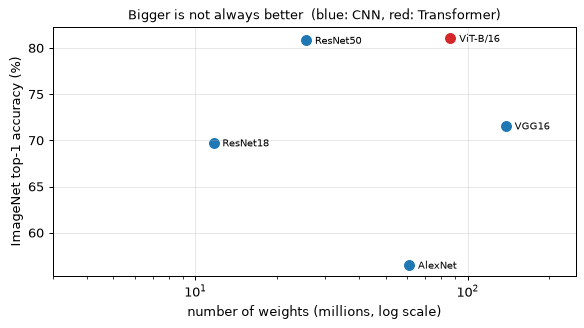

In [7]:
#@title 🎨 가중치 수 vs 정확도 그림
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for label, r in res.iterrows():
    color = "C3" if "ViT" in label else "C0"
    ax.scatter(r["가중치 수(백만)"], r["ImageNet 정확도(%)"], s=60, color=color)
    ax.annotate(label.split(" (")[0], (r["가중치 수(백만)"], r["ImageNet 정확도(%)"]),
                textcoords="offset points", xytext=(7, -3), fontsize=8)
ax.set_xscale("log"); ax.set_xlim(3, 250)
ax.set_xlabel("number of weights (millions, log scale)"); ax.set_ylabel("ImageNet top-1 accuracy (%)")
ax.set_title("Bigger is not always better  (blue: CNN, red: Transformer)", fontsize=10); ax.grid(alpha=0.3); plt.show()

> ✅ **확인할 것**
> - **강의 순서대로 좋아집니다.** AlexNet(2012) → VGG16(2014) → ResNet50(2015)으로 ImageNet 정확도가 56.5% → 71.6% → 80.9%로 올라갑니다. 강의의 AlexNet · VGGNet · ResNet 장이 그대로 숫자로 보입니다.
> - **크다고 비례해서 좋아지지 않습니다.** VGG16은 가중치가 1억 3,800만 개로 가장 크지만, 12분의 1 크기인 ResNet18(1,170만)과 정확도가 비슷하고 ResNet50(2,560만)보다 10%p 낮습니다. 지름길 연결로 깊게 쌓은 **구조**가 크기만큼 중요합니다.
> - 고양이 · 커피는 모두 맞히지만, 정답에 주는 **확률**(확신)은 모델마다 다릅니다. 가장 정확한 축에 드는 ResNet50이 오히려 확신은 낮습니다(고양이 34%, 커피 55%). **확신 ≠ 정확도**입니다.
> - 로켓: ImageNet 1,000종에 '로켓'이 따로 없어서 모스크(mosque) · 미사일 · 기념탑(obelisk) · 해상 시추 시설(drilling platform)로 **갈립니다.**
> - 우주비행사: **모두 틀립니다.** ViT는 봅슬레이(bobsled)에 72% 확신합니다. 모델이 좋아져도 **배우지 않은 것은 모르고**, 틀리면서도 자신 있어 할 수 있습니다.
> - 사진 1장 시간도 모델마다 다릅니다(이 실행에서는 VGG16이 가장 느림). AlexNet은 가중치가 ResNet18의 5배지만 비슷하게 빠릅니다. 가중치 대부분이 마지막 완전연결층에 있어 계산량은 적기 때문입니다. 위성영상처럼 사진 수십만 장을 처리하면 **속도 · 크기가 곧 비용**입니다. 실습 4에서 언어모델로 같은 비교를 합니다.
> - **ViT는 Transformer**입니다. 실습 2에서 볼 Transformer가 문장뿐 아니라 사진에도 쓰입니다. 실습 2 · 3단계에서 ViT의 [CLS] 벡터를 꺼내 위성영상을 분류합니다.

### ✏️ 직접 해보기
다른 모델도 이름만 넣으면 됩니다. 아래 칸의 `#`를 지우고 실행하세요. 쓸 수 있는 이름은 `models.list_models(module=models)`로 볼 수 있습니다.

In [8]:
# compare({"VGG19 (2014)": "vgg19", "ResNet101 (2015)": "resnet101"}, photos)

---
## 2단계. CNN 들여다보기 (5분)
### 2-1. 필터를 사진에 직접 곱해 더하기
강의 '필터: 무늬를 찾는 작은 돋보기' 장의 숫자 예(왼쪽 밝음 10, 오른쪽 어두움 0)에 **[1, 0, −1] 필터**를 대면, 경계에서만 30이 나왔습니다. 같은 계산을 컴퓨터로 해 봅니다.

In [9]:
img6 = torch.tensor([[10, 10, 10, 0, 0, 0]] * 6, dtype=torch.float32)   # 강의 장의 6×6 사진
vertical = torch.tensor([[1, 0, -1]] * 3, dtype=torch.float32)           # 세로 경계 필터
out = F.conv2d(img6[None, None], vertical[None, None])                   # 필터를 한 칸씩 옮기며 곱해 더하기
print("사진(6×6):\n", img6.int().numpy(), "\n\n필터(3×3):\n", vertical.int().numpy(), "\n\n결과(4×4):\n", out[0, 0].int().numpy())

사진(6×6):
 [[10 10 10  0  0  0]
 [10 10 10  0  0  0]
 [10 10 10  0  0  0]
 [10 10 10  0  0  0]
 [10 10 10  0  0  0]
 [10 10 10  0  0  0]] 

필터(3×3):
 [[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]] 

결과(4×4):
 [[ 0 30 30  0]
 [ 0 30 30  0]
 [ 0 30 30  0]
 [ 0 30 30  0]]


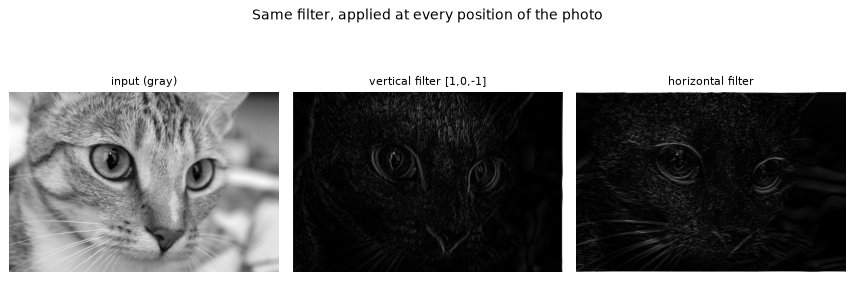

In [10]:
# 같은 필터를 고양이 사진에 (흑백으로 바꿔서)
gray = torch.from_numpy(skdata.chelsea().mean(axis=2)).float()
horizontal = vertical.T                                                  # 가로 경계 필터
v = F.conv2d(gray[None, None], vertical[None, None], padding=1)[0, 0].abs()
h = F.conv2d(gray[None, None], horizontal[None, None], padding=1)[0, 0].abs()
show_row([gray, v, h], ["input (gray)", "vertical filter [1,0,-1]", "horizontal filter"], size=3.2, cmap="gray",
         suptitle="Same filter, applied at every position of the photo")

> ✅ 세로 필터는 수염 · 눈 가장자리 같은 **세로 경계**에서, 가로 필터는 **가로 경계**에서 밝게 나옵니다.
> 여기서는 필터 숫자를 **사람이 정했습니다.** CNN은 이 숫자를 **데이터로 배웁니다.** 다음 칸에서 확인합니다.

### 2-2. ResNet18이 스스로 배운 1층 필터 64개

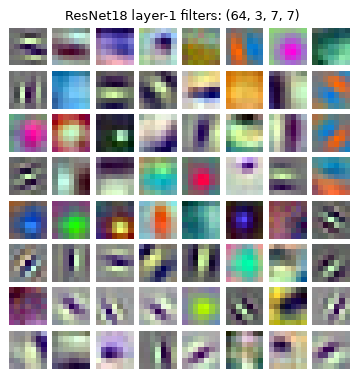

In [11]:
w = cnn.conv1.weight                                  # (64개 필터, 3색, 7, 7)
grid = np.ones((8 * 8, 8 * 8, 3))
for k in range(64):
    r, c = divmod(k, 8)
    grid[r * 8:r * 8 + 7, c * 8:c * 8 + 7] = norm01(w[k].permute(1, 2, 0).numpy())
plt.figure(figsize=(5, 5)); plt.imshow(grid); plt.axis("off")
plt.title(f"ResNet18 layer-1 filters: {tuple(w.shape)}", fontsize=10); plt.show()

> ✅ 아무도 "경계를 찾아라"라고 시키지 않았는데, **방향 있는 줄무늬**(경계 필터)와 **색 덩어리**가 저절로 생겼습니다.
> 2-1에서 사람이 정한 [1, 0, −1] 필터와 닮은 것도 보입니다. 강의 'Preview' 장의 VGG-16 Conv1_1 그림과 같은 모습입니다.

### 2-3. 층마다 나오는 특징 맵
고양이 사진을 넣고, 층(layer1 → layer4)을 지날 때마다 나오는 **특징 맵**을 몇 장씩 꺼내 봅니다.

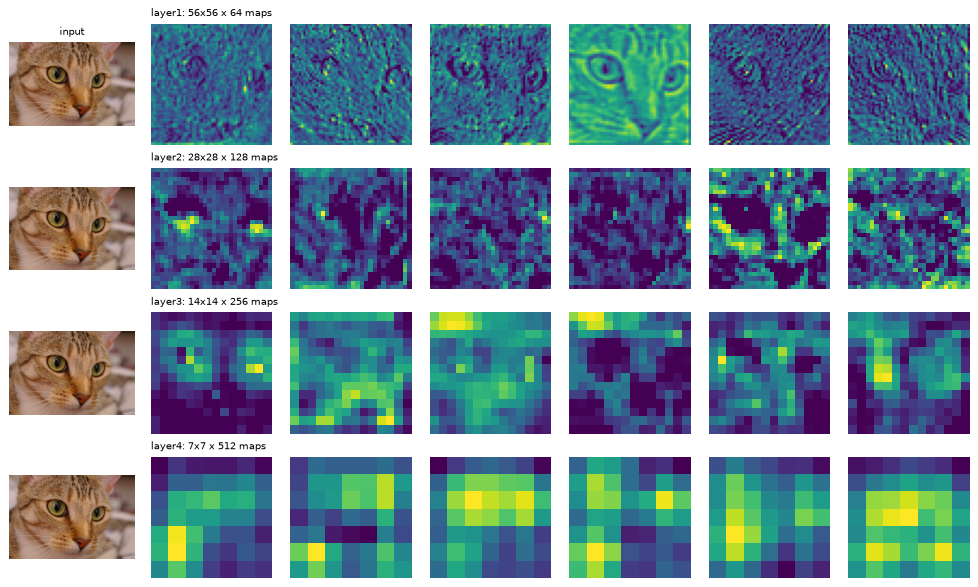

In [12]:
feats = {}
hooks = [getattr(cnn, name).register_forward_hook(lambda m, i, o, name=name: feats.__setitem__(name, o[0]))
         for name in ["layer1", "layer2", "layer3", "layer4"]]
cnn(preprocess(torch.from_numpy(skdata.chelsea()).permute(2, 0, 1))[None])
for hk in hooks: hk.remove()

fig, axes = plt.subplots(4, 7, figsize=(11, 6.6))
for row, (name, f) in enumerate(feats.items()):
    axes[row, 0].imshow(skdata.chelsea()); axes[row, 0].set_title("input" if row == 0 else "", fontsize=8)
    top = f.mean(dim=(1, 2)).topk(6).indices                 # 가장 많이 켜진 채널 6개
    for j, ch in enumerate(top):
        axes[row, j + 1].imshow(f[ch].numpy(), cmap="viridis")
    axes[row, 1].set_title(f"{name}: {f.shape[1]}x{f.shape[2]} x {f.shape[0]} maps", fontsize=8, loc="left")
for ax in axes.ravel(): ax.axis("off")
fig.tight_layout(); plt.show()

> ✅ **확인할 것**
> - **앞 층**(layer1)은 사진 모양이 그대로 보이고 **경계 · 질감**에 반응합니다.
> - 뒤로 갈수록 **크기는 작아지고(56 → 7) 장 수는 많아집니다(64 → 512).** 위치보다 "**무엇이 있나**"만 남습니다. 강의 '층을 쌓으면: 선 → 모양 → 물체' 장, 'Preview' 장과 같은 흐름입니다.
>
> 🤔 마지막 7×7 특징 맵 512장을 평균 내면 숫자 512개가 됩니다. 이것이 사진의 '**특징**'입니다. 이 숫자 위에 **로지스틱 회귀**를 얹으면 사진 몇백 장으로도 새 분류를 배울 수 있습니다(전이학습). 실습 2 · 3단계에서 ViT로 직접 해 보고, 실습 3의 4단계(문장 → 숫자 768개 → 로지스틱 회귀)도 같은 구조입니다.

---
## ✨ 도전: Gemini로 이 노트북 바꿔 보기 (5분)
코드를 직접 고치지 않고, Colab의 **✦ Gemini**에게 말로 시켜 봅니다. 먼저 **파일 → Drive에 사본 저장**으로 내 사본을 만드세요(Google 로그인 필요).

아래 중 하나를 Gemini 창에 입력해 보세요.
1. "ResNet18 대신 vgg16으로 사진 4장을 다시 분류하고, 두 모델 결과를 표로 비교해 줘"
2. "MODELS에 vgg19와 resnet101을 추가해서 비교표와 그림을 다시 만들어 줘"
3. "2단계의 세로 필터 [1, 0, −1] 대신 대각선 경계를 찾는 필터를 만들어서 고양이 사진에 적용해 줘"
4. "1단계 사진 4장에 scikit-image의 다른 예시 사진 2장을 더해서 다시 분류해 줘"

> ⚠️ Gemini가 만든 코드는 **읽어 보고** 실행하세요. 오류가 나면 "이 오류를 고쳐 줘"라고 다시 시키면 됩니다. 결과의 해석과 숫자 확인은 사람 몫입니다.

---
## 마무리
### 오늘의 핵심
- **추론** = 학습된 가중치를 그대로 두고 새 입력의 답을 계산 (회귀식에 새 x 넣기)
- **CNN**: 필터를 곱해 더하는 계산을 사진 전체에 반복. 1층은 경계 · 색, 뒤 층으로 갈수록 "무엇이 있나"
- **모델 바꾸기**: 코드는 그대로, 이름만 바꿔도 답 · 확신 · 속도가 달라짐. 크다고 더 정확한 것은 아님
- 다음: RNN · Transformer 강의 뒤 **실습 2**에서 빈칸 맞히기 · Self-attention · ViT [CLS] 토큰으로 분류

### 국가통계와의 연결
- **CNN** → 위성 · 항공사진 분류 (호주 통계청 주소 유형 분류 · 7교시)